<a href="https://colab.research.google.com/github/AkashDAVLabs/DAV-lab-programs/blob/main/decision_tree_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving Breast_Cancer.csv to Breast_Cancer (1).csv
First 5 rows of the dataset:
   Age   Race Marital Status T Stage N Stage 6th Stage  \
0   68  White        Married      T1      N1       IIA   
1   50  White        Married      T2      N2      IIIA   
2   58  White       Divorced      T3      N3      IIIC   
3   58  White        Married      T1      N1       IIA   
4   47  White        Married      T2      N1       IIB   

               differentiate Grade   A Stage  Tumor Size Estrogen Status  \
0      Poorly differentiated     3  Regional           4        Positive   
1  Moderately differentiated     2  Regional          35        Positive   
2  Moderately differentiated     2  Regional          63        Positive   
3      Poorly differentiated     3  Regional          18        Positive   
4      Poorly differentiated     3  Regional          41        Positive   

  Progesterone Status  Regional Node Examined  Reginol Node Positive  \
0            Positive                      

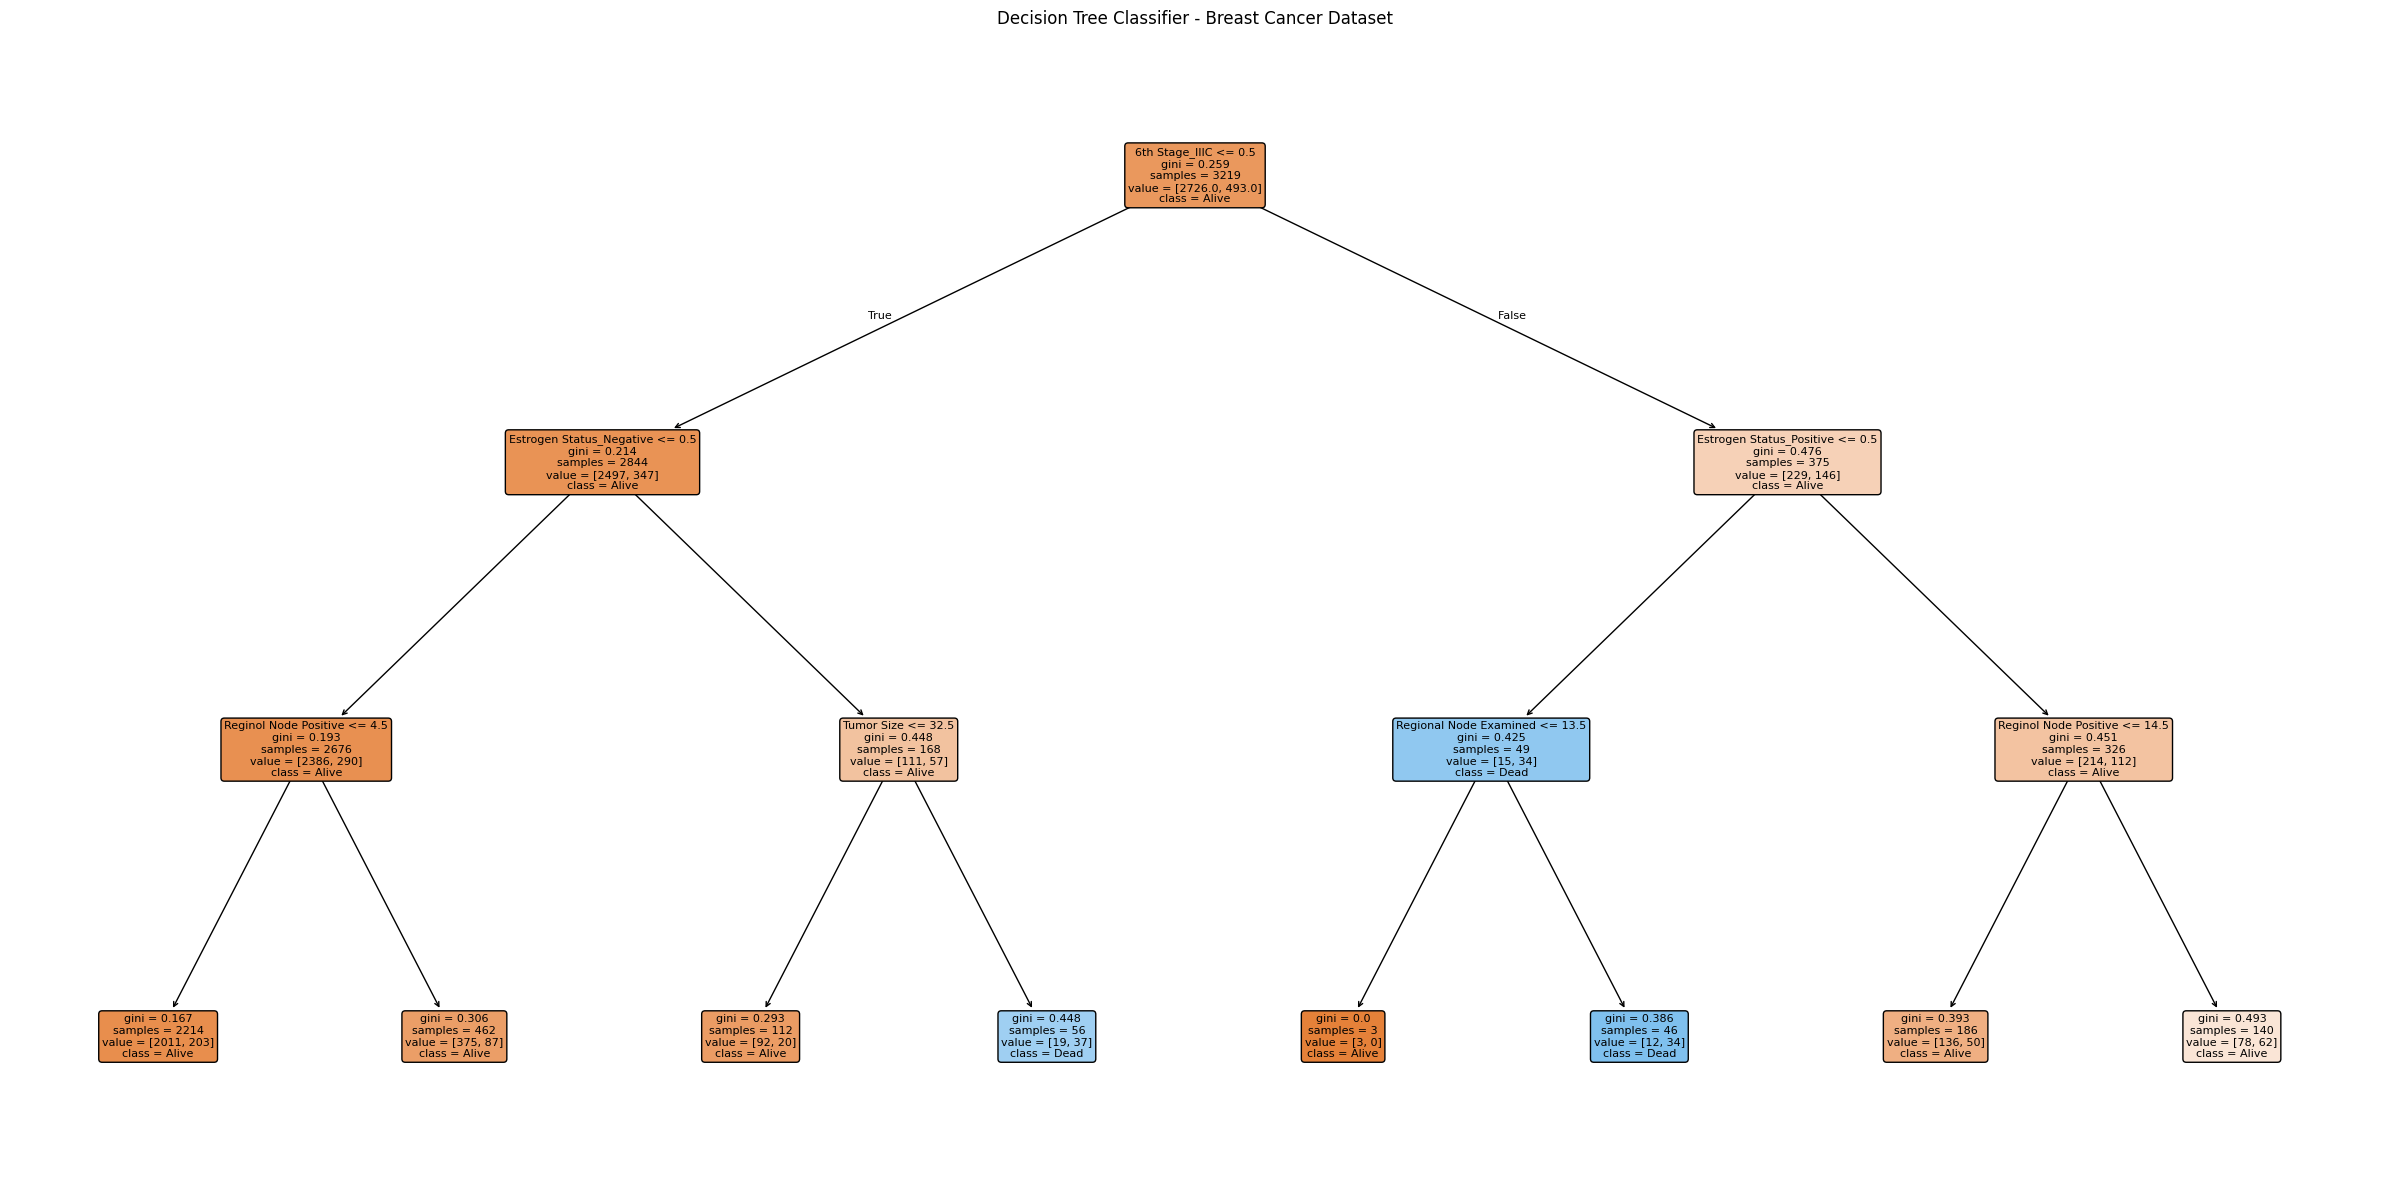

In [2]:


# DECISION TREE CLASSIFIER - BREAST CANCER DATASET


# STEP 1: Import the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)


# STEP 2: Upload and load the dataset


uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

# Clean column names by removing extra spaces
df.columns = df.columns.str.strip()

print("First 5 rows of the dataset:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values in each column:")
print(df.isnull().sum())

# STEP 3: Prepare features and target

# Target column to predict
target_column = "Status"

# Remove rows with missing target values, if any
df = df.dropna(subset=[target_column]).copy()

# Exclude Survival Months to avoid target leakage.
# It can reveal information about the outcome being predicted.
X = df.drop(columns=[target_column, "Survival Months"])

y = df[target_column].astype(str)

# Fill missing numerical values with the median
numeric_columns = X.select_dtypes(include=np.number).columns

for col in numeric_columns:
    X[col] = X[col].fillna(X[col].median())

# Fill missing categorical values with the most frequent value
categorical_columns = X.select_dtypes(
    include=["object", "category", "bool"]
).columns

for col in categorical_columns:
    mode_values = X[col].mode()
    if not mode_values.empty:
        X[col] = X[col].fillna(mode_values.iloc[0])
    else:
        X[col] = X[col].fillna("Unknown")

# Convert categorical columns into numerical columns
X = pd.get_dummies(X, drop_first=False, dtype=int)

print("\nPrepared feature shape:", X.shape)
print("\nTarget class distribution:")
print(y.value_counts())

print("\nEncoded feature columns:")
print(X.columns.tolist())

# STEP 4: Split the dataset into training and testing sets


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# STEP 5: Create and train the Decision Tree model


model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

model.fit(X_train, y_train)

print("\nDecision Tree model trained successfully!")


# STEP 6: Make predictions
y_pred = model.predict(X_test)

print("\nFirst 10 actual values:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted values:")
print(y_pred[:10].tolist())


# STEP 7: Evaluate the model


accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:", round(accuracy, 4))
print("Accuracy percentage:", round(accuracy * 100, 2), "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=model.classes_))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=model.classes_,
        target_names=model.classes_,
        zero_division=0
    )
)

# STEP 8: Visualize the Decision Tree


plt.figure(figsize=(24, 12))

plot_tree(
    model,
    feature_names=X.columns.tolist(),
    class_names=model.classes_.tolist(),
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Classifier - Breast Cancer Dataset")
plt.tight_layout()
plt.show()
